# Rebuttle for Case 1
- proof-of-concept: corsely resolved plume, sparse well measurement, damaged geo data
- plot contours, profiles, overall statistical metrics, posterior diversity in the main text, no sensivity analysis
- plot other sensivity analysis in the si

In [2]:
%env CUDA_VISIBLE_DEVICES = 3

import torch
import numpy as np
import h5py
import matplotlib.pyplot as plt
import seaborn as sns

from functools import partial
import sys
sys.path.append("../../..")
from ConditionalDiffusionGeneration.src.guided_diffusion.unet import create_model
from ConditionalDiffusionGeneration.src.guided_diffusion.condition_methods import get_conditioning_method
from ConditionalDiffusionGeneration.src.guided_diffusion.measurements import get_noise, get_operator
from ConditionalDiffusionGeneration.src.guided_diffusion.gaussian_diffusion import create_sampler
from einops import rearrange

torch.manual_seed(42)
np.random.seed(42)
device = torch.device("cuda")

# define my own color
from matplotlib.colors import LinearSegmentedColormap
import json
with open("../cmap.json", "r") as f:
    cmap_json = json.load(f)[0]
rgb_points = np.array(cmap_json["RGBPoints"]).reshape(-1, 4)
x = rgb_points[:, 0]
r = rgb_points[:, 1]
g = rgb_points[:, 2]
b = rgb_points[:, 3]
colors = list(zip(x, zip(r, g, b)))
mycmap = LinearSegmentedColormap.from_list("CoolToWarmExtended", colors)

env: CUDA_VISIBLE_DEVICES=3


## diffusion

In [ ]:
u_net_model = create_model(image_size= 64,
                           num_channels= 64,
                           num_res_blocks= 2,
                           num_heads=8,
                           num_head_channels=32,
                           attention_resolutions="32,16,8,4,2,1",
                           channel_mult="1,1,2,2,4,4",
                           learn_sigma=True,
                           model_path='../../../UnconditionalDiffusionTraining_and_Generation/output/logs_unet_experiment1/ema.pt'
                        )

u_net_model.to(device)
u_net_model.eval()
print('loaded unet')

In [ ]:
operator =  get_operator(name='cartesian_sparse_measurement_all',
                        device=device,
                        ckpt_path='../../../ConditionalNeuralField/output_Cartesian_simple/all3_small/checkpoint.pt',
                        norm_record_path='../../../ConditionalNeuralField/output_Cartesian_simple/all3_small/normalizer_params.pt',
                        simdata_path='../../../Dataset/Cartesian_all3_small.npy',
                        simdata_idx=1998,
                        num_probed=5
                        )
noiser = get_noise(sigma=0.0, name='gaussian')

In [ ]:
cond_method = get_conditioning_method(operator=operator, noiser=noiser, name='ps_adam', scale=1e-2)    # 1e-2
measurement_cond_fn = partial(cond_method.conditioning)

sampler = create_sampler(sampler='ddpm',
                         steps=1000,
                         noise_schedule="cosine",
                         model_mean_type="epsilon",
                         model_var_type="learned_range",
                         dynamic_threshold=False,
                         clip_denoised=True,
                         rescale_timesteps=False,
                         timestep_respacing="")
sample_fn = partial(sampler.p_sample_loop, model=u_net_model, measurement_cond_fn=measurement_cond_fn)

no_of_samples = 10
time_length = 64
latent_size = 256

In [ ]:
x_start = torch.randn(no_of_samples, 1, time_length, latent_size, device=device)
measurement_ref = operator.sparse_cartesian_measurement()
samples = [sample_fn(x_start=x_start[i:i+1], measurement=measurement_ref, record=False, save_root=None) for i in range(x_start.shape[0])]

In [ ]:
gen_latents = torch.cat(samples)
gen_latents = operator._unnorm(gen_latents)
gen_latents = gen_latents[:,0]
print(f"Generated latents shape: {gen_latents.shape}")
torch.save(gen_latents, 'conditional_outputs/[rebuttle]pts/latent_sparse5.pt')

## neural field

In [ ]:
from ConditionalNeuralField.cnf.nf_networks import SIRENAutodecoder_mdf_film
nf = SIRENAutodecoder_mdf_film(omega_0=5,
                                in_coord_features=2,
                                in_latent_features=256,
                                out_features=3,
                                num_hidden_layers=5,
                                hidden_features=128)
ckpt = torch.load("../../../ConditionalNeuralField/output_Cartesian_simple/all3_small/checkpoint.pt")
nf.load_state_dict(ckpt['model_state_dict'])
nf.eval()
nf.to(device)
del ckpt
print('nf loaded')

In [ ]:
whole_coords = operator._gene_cartesian_coord()
whole_coords_in = whole_coords.unsqueeze(0).to(device)
gen_latents_in = rearrange(gen_latents, 'b t l -> (b t) 1 1 l' )
gen_latents_in = gen_latents_in.to(device)
with torch.no_grad():
    nf_out_gene = nf(whole_coords_in, gen_latents_in)
nf_out_gene = operator._unnorm_cnf(nf_out_gene)
nf_out_gene = nf_out_gene.reshape(no_of_samples, time_length, 64, 64, 3)
print(f"CNF output shape: {nf_out_gene.shape}")
torch.save(nf_out_gene, 'conditional_outputs/[rebuttle]pts/CNF_out_sparse5.pt')

# **analysis**

In [2]:
gt = torch.from_numpy(np.load('../../../Dataset/Cartesian_all3_small.npy')[1998]).cpu()
superres_pt = torch.load('conditional_outputs/[rebuttle]pts/CNF_out_superresolution.pt', map_location='cpu')
sparse_pt = torch.load('conditional_outputs/[rebuttle]pts/CNF_out_sparse5.pt', map_location='cpu')
inpaint_pt = torch.load('conditional_outputs/[rebuttle]pts/CNF_out_inpainting.pt', map_location='cpu')
print(gt.shape, superres_pt.shape, sparse_pt.shape, inpaint_pt.shape)


superres_sim = h5py.File("conditional_outputs/[rebuttle]pts/Cartesian_superresolution_check.hdf5")
sparse_sim = h5py.File("conditional_outputs/[rebuttle]pts/Cartesian_sparse5_check.hdf5")
inpaint_sim = h5py.File("conditional_outputs/[rebuttle]pts/Cartesian_inpainting_check.hdf5")
print(superres_sim.keys())
print(superres_sim['permeability_log'].shape, superres_sim['saturation'].shape, type(superres_sim['saturation']))

torch.Size([64, 64, 64, 3]) torch.Size([10, 64, 64, 64, 3]) torch.Size([10, 64, 64, 64, 3]) torch.Size([10, 64, 64, 64, 3])
<KeysViewHDF5 ['permeability', 'permeability_log', 'pressure', 'saturation', 'time_step']>
(10, 64, 64) (10, 64, 64, 64) <class 'h5py._hl.dataset.Dataset'>


In [44]:
def get_mean_std(input):
    mean = torch.mean(input, dim=0)
    std = torch.std(input, dim=0)
    return mean, std

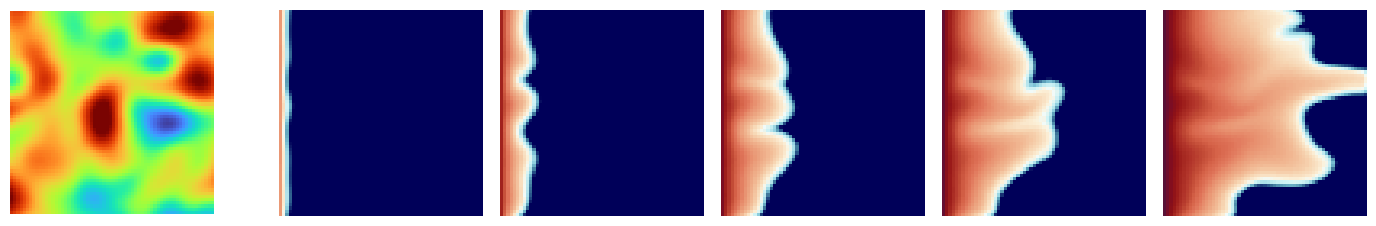

In [146]:
def make_gt_1x3(figsize=(18, 3), width_space=0.25, height_space=0.0):
    import matplotlib.gridspec as gridspec

    fig = plt.figure(figsize=figsize, constrained_layout=False)

    gs = gridspec.GridSpec(1, 7, width_ratios=[1, 0.15, 1, 1, 1, 1, 1], wspace=width_space, hspace=height_space)

    axes = []

    ax = fig.add_subplot(gs[0])
    ax.set_aspect('equal')
    ax.axis('off')
    axes.append(ax)
    for col in range(2, 7):
        ax = fig.add_subplot(gs[col])
        ax.set_aspect('equal')
        ax.axis('off')
        axes.append(ax)
    
    return fig, axes

def make_gt_1x6_contour(gt_tensor, figsize=(18, 3), width_space=0.25, height_space=0.0):
    fig, axes = make_gt_1x3(figsize=figsize, width_space=width_space, height_space=height_space)

    ts = [3, 12, 25, 38, 63]

    axes[0].imshow(gt_tensor[:, ..., -1].mean(dim=0), vmin=1.5, vmax=6.5, cmap='turbo')

    for i, ts in enumerate(ts):
        axes[i+1].imshow(gt_tensor[ts, :, :-1, 1], vmin=0, vmax=0.6, cmap=mycmap)
    
    return fig, axes

fig, axes = make_gt_1x6_contour(gt, figsize=(17.5, 5.5), width_space=0.1, height_space=0.08)
fig.savefig('conditional_outputs/[rebuttle]figs/gt_contour.pdf', bbox_inches='tight')

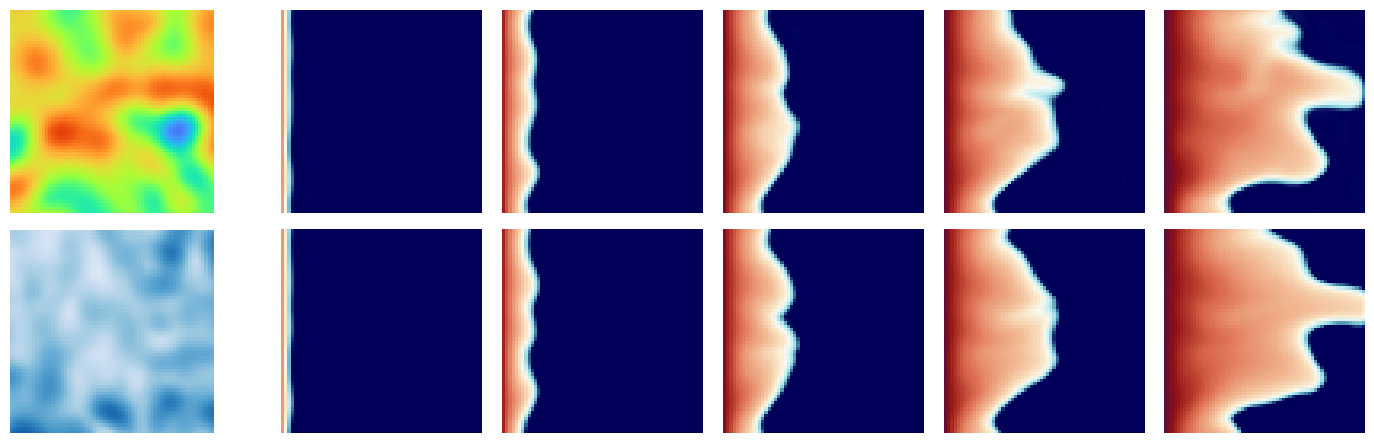

In [147]:
def make_2x6(figsize=(18, 6), width_space=0.25, height_space=0.2):
    import matplotlib.gridspec as gridspec

    fig = plt.figure(figsize=figsize, constrained_layout=False)

    gs = gridspec.GridSpec(2, 7, width_ratios=[1, 0.15, 1, 1, 1, 1, 1], wspace=width_space, hspace=height_space)

    axes = []

    for row in range(2):
        row_axes = []
        ax = fig.add_subplot(gs[row, 0])
        ax.set_aspect('equal')
        ax.axis('off')
        row_axes.append(ax)
        for col in range(2, 7):
            ax = fig.add_subplot(gs[row, col])
            ax.set_aspect('equal')
            ax.axis('off')
            row_axes.append(ax)
        axes.append(row_axes)
    
    return fig, axes

def make_2x6_contour(generated_tensor, simulated_h5, show_idx=0, figsize=(18, 6), width_space=0.25, height_space=0.2):
    fig, axes = make_2x6(figsize=figsize, width_space=width_space, height_space=height_space)

    std_k = generated_tensor.mean(dim=1).std(dim=0)

    ts = [3, 12, 25, 38, 63]

    axes[0][0].imshow(generated_tensor[show_idx, :, ..., -1].mean(dim=0), vmin=1.5, vmax=6.5, cmap='turbo')
    axes[1][0].imshow(std_k[..., -1], vmin=0, vmax=0.8, cmap="Blues")

    for i, ts in enumerate(ts):
        axes[0][i+1].imshow(generated_tensor[show_idx, ts, :, :-1, 1], vmin=0, vmax=0.6, cmap=mycmap)
        axes[1][i+1].imshow(simulated_h5['saturation'][show_idx][ts][:, :-1],  vmin=0, vmax=0.6, cmap=mycmap)
    
    return fig, axes

fig, axes = make_2x6_contour(superres_pt, superres_sim, show_idx=7, figsize=(17.5, 5.5), width_space=0.1, height_space=0.08)
fig.savefig('conditional_outputs/[rebuttle]figs/superres_contour.pdf', bbox_inches='tight')

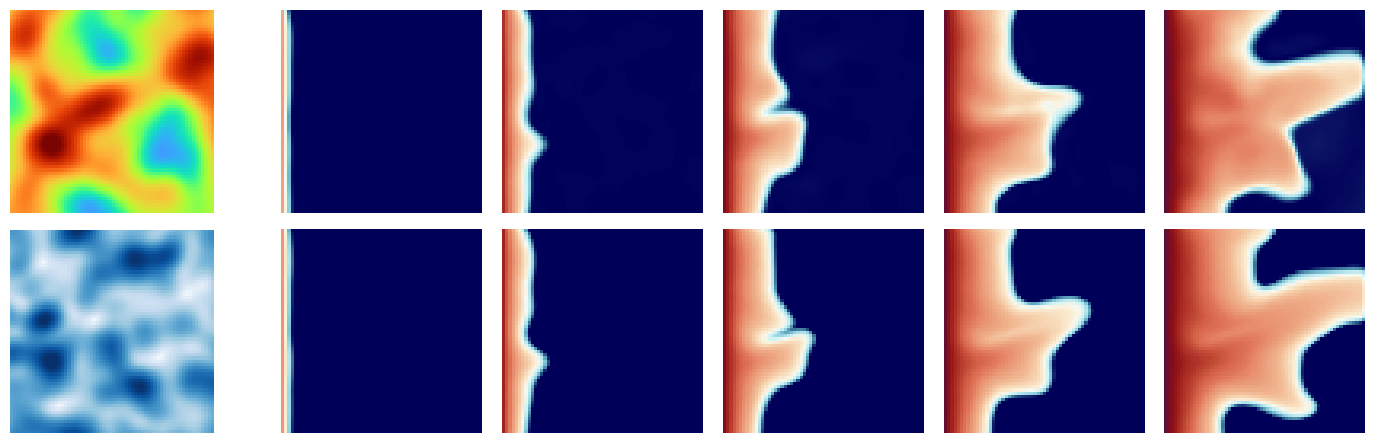

In [662]:
fig, axes = make_2x6_contour(sparse_pt, sparse_sim, show_idx=4, figsize=(17.5, 5.5), width_space=0.1, height_space=0.08) #1
fig.savefig('conditional_outputs/[rebuttle]figs/sparse_contour.pdf', bbox_inches='tight')

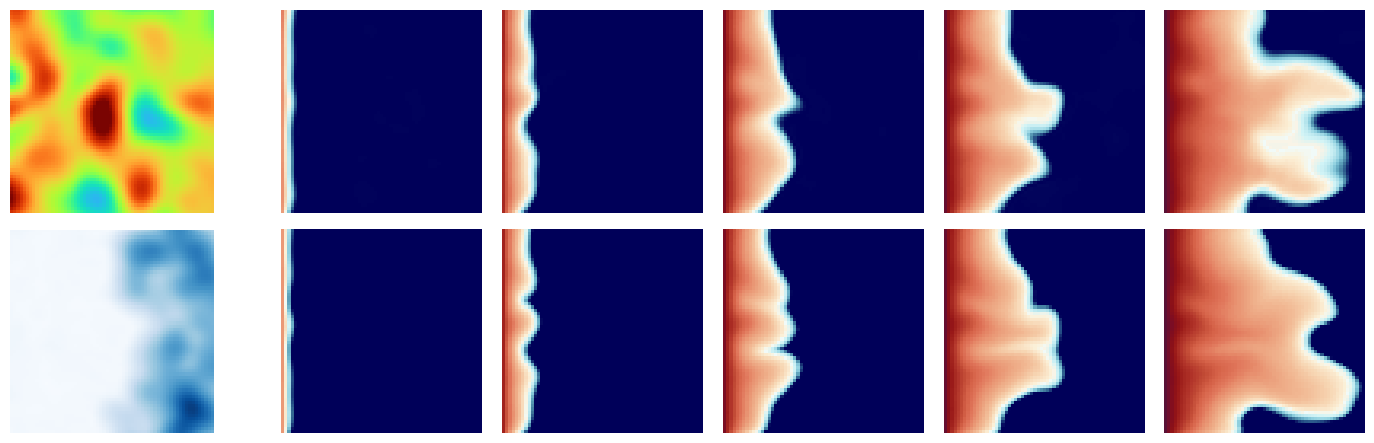

In [149]:
fig, axes = make_2x6_contour(inpaint_pt, inpaint_sim, show_idx=3, figsize=(17.5, 5.5), width_space=0.1, height_space=0.08)
# axes[1][0].plot(boundary, np.arange(64), 'k', linewidth=1.5, alpha=0.8)
fig.savefig('conditional_outputs/[rebuttle]figs/inpaint_contour.pdf', bbox_inches='tight')

torch.Size([1, 64, 8, 8])


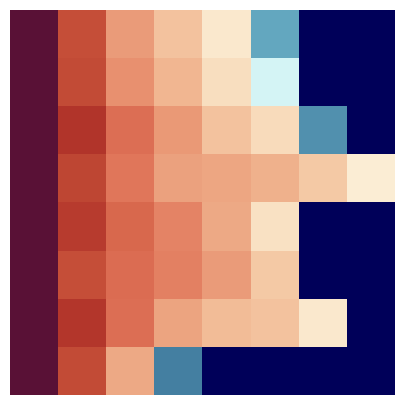

In [17]:
import torch.nn.functional as F

downsampled = F.interpolate(gt[:, :, :, 1].unsqueeze(0), size=(8, 8), mode='nearest')
print(downsampled.shape)

plt.figure(figsize=(5, 5))

plt.imshow(downsampled[0, -1], vmin=0, vmax=0.6, cmap=mycmap)
ax = plt.gca()
ax.set_aspect('equal')
plt.axis('off')
plt.savefig('conditional_outputs/[rebuttle]figs/superres_condition.pdf', bbox_inches='tight')

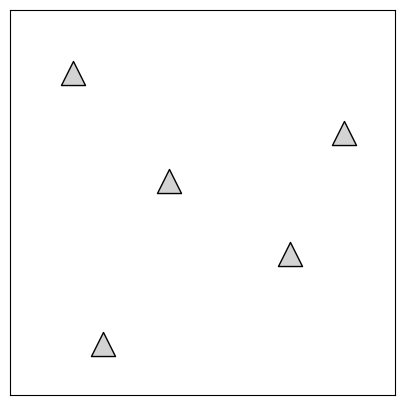

In [31]:
pts = [(10, 10), (20, 55), (28, 26), (40, 46), (55, 15)]

plt.figure(figsize=(5, 5))
plt.imshow(np.full((64, 64), np.nan), cmap="Greys", alpha=0)
for y, x in pts:
    plt.scatter(x, y, color='lightgray', marker='^', s=300, edgecolors='k')
ax = plt.gca()
ax.set_aspect('equal')
plt.xticks([])
plt.yticks([])
plt.savefig('conditional_outputs/[rebuttle]figs/sparse_condition.pdf', bbox_inches='tight')

37 34


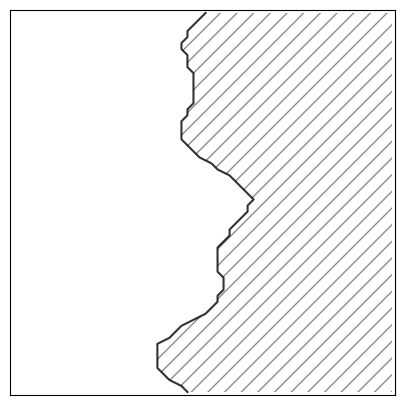

In [3]:
from matplotlib.path import Path
import matplotlib.patches as patches

def generate_boundary_mask(h, w, boundary_x=40, perturbation_amplitude=8, n_modes=5, seed=42):
    rng = np.random.RandomState(seed)
    mask_np = np.ones((h, w), dtype=np.float32)
    rows = np.arange(h)
    t = rows / h * 2 * np.pi
    perturbation = np.zeros(h)
    for _ in range(n_modes):
        freq = rng.uniform(1, 4)
        amplitude = rng.uniform(0.3, 1.0)
        phase = rng.uniform(0, 2 * np.pi)
        perturbation += amplitude * np.sin(freq * t + phase)
    if perturbation.max() - perturbation.min() > 0:
        perturbation = 2 * (perturbation - perturbation.min()) / (perturbation.max() - perturbation.min()) - 1
    perturbation *= perturbation_amplitude
    boundary = boundary_x + perturbation
    boundary = np.clip(boundary, 1, w - 1).astype(int)
    for i in range(h):
        mask_np[i, boundary[i]:] = 0.0
    n_masked = (mask_np == 0).sum()
    return mask_np, n_masked, boundary

mask, n_masked, boundary = generate_boundary_mask(64, 64, boundary_x=32, perturbation_amplitude=8, n_modes=6, seed=55)

plt.figure(figsize=(5, 5))
plt.imshow(mask, cmap='gray', alpha=0)
plt.plot(boundary, np.arange(64), 'k', linewidth=1.5, alpha=0.8)
 
verts = []
for i in range(64):
    verts.append((boundary[i], i))
verts.append((63, 63))
verts.append((63, 0))
verts.append((boundary[0], 0))
 
codes = [Path.MOVETO] + [Path.LINETO] * (len(verts) - 2) + [Path.CLOSEPOLY]
 
patch = patches.PathPatch(
    Path(verts, codes),
    facecolor='none',
    edgecolor='gray',
    hatch='//',
    linewidth=0,
    alpha=0.9
)
 
ax = plt.gca()
ax.add_patch(patch)
ax.set_aspect('equal')
plt.xticks([])
plt.yticks([])
print(boundary[28], boundary[26])

plt.savefig('conditional_outputs/[rebuttle]figs/inpaint_condition.pdf', bbox_inches='tight')

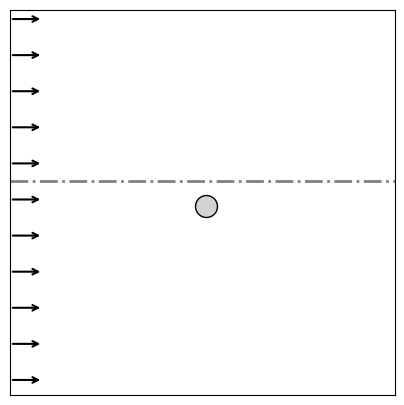

In [423]:
plt.figure(figsize=(5, 5))
ax = plt.gca()
plt.imshow(np.full((64, 64), np.nan), cmap="Greys", alpha=0)

plt.axhline(y=28, ls='-.', lw=2, c='gray')
plt.scatter(32, 32, s=250, c='lightgray', marker='o', edgecolors='k', zorder=100)
for y in np.arange(1, 64, 6):
    ax.annotate('', xy=(5, y), xytext=(-0.5, y),
                arrowprops=dict(arrowstyle='->', color='k', lw=1.5))


ax.set_aspect('equal')
plt.xticks([])
plt.yticks([])
plt.savefig('conditional_outputs/[rebuttle]figs/gt_condition.pdf', bbox_inches='tight')

## statistics

In [6]:
def make_1x3(figsize=(10, 3), width_space=0.3, height_space=0.0):
    import matplotlib.gridspec as gridspec

    fig = plt.figure(figsize=figsize, constrained_layout=False)

    gs = gridspec.GridSpec(1, 3, width_ratios=[1, 1, 1], wspace=width_space, hspace=height_space)

    axes = []

    for i in range(3):
        ax = fig.add_subplot(gs[i])
        ax.spines['right'].set_visible(False)
        ax.spines['top'].set_visible(False)
        if i > 0:
            ax.tick_params(labelleft=False)

        ax.set_box_aspect(1)
        axes.append(ax)
    
    return fig, axes

torch.Size([64]) torch.Size([64])


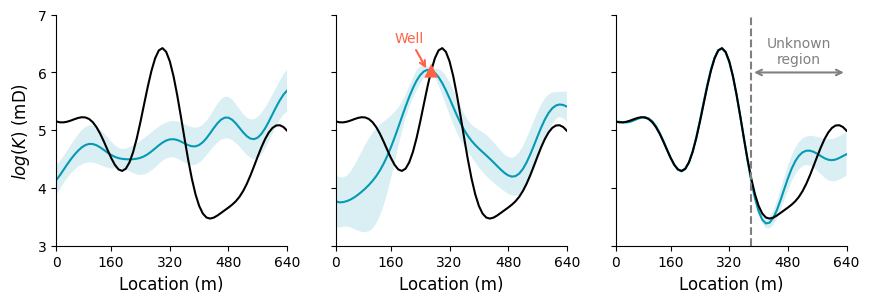

In [6]:
fig, axes = make_1x3(figsize=(10.5, 3), width_space=0.1)

def get_kline_mean_std(generation):
    k_mean, k_std = get_mean_std(generation.mean(dim=1)[...,-1])
    return k_mean[28, :], k_std[28, :]

def fill_between(ax, mean, std, color='grey'):
    ax.fill_between(np.arange(len(mean)), mean - std*1, mean + std*1, color=color, alpha=0.15, edgecolor='none')

sup_kline_mean, sup_kline_std = get_kline_mean_std(superres_pt)
sp_kline_mean, sp_kline_std = get_kline_mean_std(sparse_pt)
ip_kline_mean, ip_kline_std = get_kline_mean_std(inpaint_pt)
gt_kline = gt.mean(dim=0)[28, :, -1]
print(sup_kline_mean.shape, gt_kline.shape)

line_color= "#0499b4"

axes[0].plot(sup_kline_mean, c=line_color, lw=1.5)
axes[0].plot(gt_kline, c='k', lw=1.5)
fill_between(axes[0], sup_kline_mean, sup_kline_std, color=line_color)

axes[1].plot(sp_kline_mean, c=line_color, lw=1.5)
axes[1].plot(gt_kline, c='k', lw=1.5)
fill_between(axes[1], sp_kline_mean, sp_kline_std, color=line_color)
axes[1].scatter(26, gt_kline[26], color='tomato', marker='^', s=100, edgecolors='none', zorder=100, alpha=1.0)
axes[1].annotate('Well', xy=(25, gt_kline[26]), xytext=(26 - 10, gt_kline[26] + 0.5),
                 arrowprops=dict(arrowstyle='->', color='tomato', lw=1.5), fontsize=10, color='tomato')


axes[2].plot(ip_kline_mean, c=line_color, lw=1.5)
axes[2].plot(gt_kline, c='k', lw=1.5)
fill_between(axes[2], ip_kline_mean, ip_kline_std, color=line_color)
axes[2].axvline(37, lw=1.5, ls='--', c='grey')
axes[2].annotate('', xy=(63, 6), xytext=(37, 6),
                 arrowprops=dict(arrowstyle='<->', color='grey', lw=1.5))
axes[2].text((37 + 63) / 2, 6.1, 'Unknown\nregion', ha='center', va='bottom',
             fontsize=10, color='grey')

labels = [0, 160, 320, 480, 640]
positions = [int(x * 63 / 640) for x in labels]
for a in axes:
    a.set_ylim(3, 7)
    a.set_xlim(0, 63)
    a.set_xticks(ticks=positions, labels=[str(x) for x in labels])
    a.set_xlabel('Location (m)', fontsize=12)
    a.set_yticks([3, 4, 5, 6, 7])
axes[0].set_ylabel('$log(K)$ (mD)', fontsize=12)

fig.savefig('conditional_outputs/[rebuttle]figs/analysis-kline.pdf', bbox_inches='tight')
plt.show()

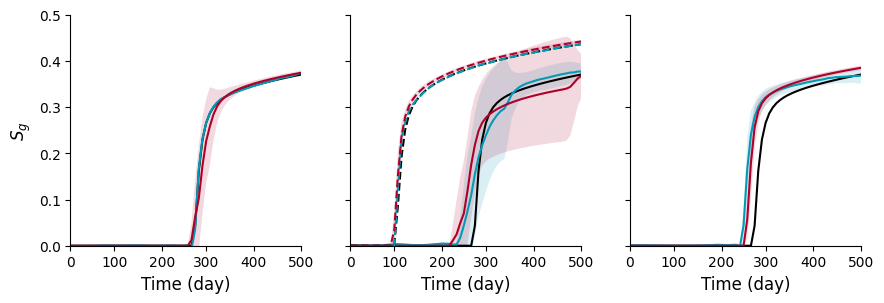

In [449]:
fig, axes = make_1x3(figsize=(10.5, 3), width_space=0.1)

query_pt = (32, 32)
well_pt = (10, 10)

for a in axes:
    a.plot(gt[:, query_pt[0], query_pt[1], 1], lw=1.5, c='k')
    a.set_ylim(0, 0.5)
    a.set_yticks([0.0, 0.1, 0.2, 0.3, 0.4, 0.5])
    labels = [0, 100, 200, 300, 400, 500]
    positions = [int(x * 63 / 500) for x in labels]
    a.set_xlim(0, 63)
    a.set_xticks(ticks=positions, labels=[str(x) for x in labels])
    a.set_xlabel('Time (day)', fontsize=12)
axes[0].set_ylabel('$S_g$', fontsize=12)


def fill_between(ax, mean, std, color='grey'):
    ax.fill_between(np.arange(len(mean)), mean - std*1, mean + std*1, color=color, alpha=0.15, edgecolor='none')

super_smean = superres_pt[:, :, query_pt[0], query_pt[1], 1].mean(dim=0)
super_sstd = superres_pt[:, :, query_pt[0], query_pt[1], 1].std(dim=0)
axes[0].plot(super_smean, lw=1.5, c=line_color)
fill_between(axes[0], super_smean, super_sstd, color=line_color)
super_sim_s = superres_sim['saturation'][:, :, query_pt[0], query_pt[1]]
axes[0].plot(super_sim_s.mean(axis=0), lw=1.5, c='#ae002a')
fill_between(axes[0], super_sim_s.mean(axis=0), super_sim_s.std(axis=0), color='#ae002a')

sp_smean = sparse_pt[:, :, query_pt[0], query_pt[1], 1].mean(dim=0)
sp_sstd = sparse_pt[:, :, query_pt[0], query_pt[1], 1].std(dim=0)
axes[1].plot(sp_smean, lw=1.5, c=line_color)
fill_between(axes[1],sp_smean, sp_sstd, color=line_color)
sp_sim_s = sparse_sim['saturation'][:, :, query_pt[0], query_pt[1]]
axes[1].plot(sp_sim_s.mean(axis=0), lw=1.5, c='#ae002a')
fill_between(axes[1], sp_sim_s.mean(axis=0), sp_sim_s.std(axis=0), color='#ae002a')

axes[1].plot(gt[:, well_pt[0], well_pt[1], 1], lw=1.5, c='k', ls='--')
sp_well = sparse_pt[:, :, well_pt[0], well_pt[1], 1]
axes[1].plot(sp_well.mean(dim=0), lw=1.5, c=line_color, ls='--')
sp_well_sim_s = sparse_sim['saturation'][:, :, well_pt[0], well_pt[1]]
axes[1].plot(sp_well_sim_s.mean(axis=0), lw=1.5, c='#ae002a', ls='--')
fill_between(axes[1], sp_well_sim_s.mean(axis=0), sp_well_sim_s.std(axis=0), color='#ae002a')


ip_smean = inpaint_pt[:, :, query_pt[0], query_pt[1], 1].mean(dim=0)
ip_sstd = inpaint_pt[:, :, query_pt[0], query_pt[1], 1].std(dim=0)
axes[2].plot(ip_smean, lw=1.5, c=line_color)
fill_between(axes[2], ip_smean, ip_sstd, color=line_color)
ip_sim_s = inpaint_sim['saturation'][:, :, query_pt[0], query_pt[1]]
axes[2].plot(ip_sim_s.mean(axis=0), lw=1.5, c='#ae002a')
fill_between(axes[2], ip_sim_s.mean(axis=0), ip_sim_s.std(axis=0), color='#ae002a')

fig.savefig('conditional_outputs/[rebuttle]figs/analysis-sline.pdf', bbox_inches='tight')

#### Variogram

In [4]:
gt_k_field = gt[0, :, :, -1]

superres_k_field = superres_pt[..., -1].mean(dim=1)
sparse_k_field = sparse_pt[..., -1].mean(dim=1)
inpatint_k_field = inpaint_pt[..., -1].mean(dim=1)
print(gt_k_field.shape, superres_k_field.shape)

def eval_vario(field):
    import gstools as gs
    x = y = np.arange(1, 65) * 10
    bin, gamma = gs.vario_estimate(
        *((x, y),),
        field.numpy(),
        mesh_type='structured'
    )
    fit_model = gs.Gaussian(dim=2)
    fit_model.fit_variogram(bin, gamma, nugget=False)
    return bin, gamma, fit_model

def eval_vario_samples(fields):
    bin_list, gamma_list, fit_model_list = [], [], []
    for i in range(fields.size(0)):
        bin, gamma, fit_model = eval_vario(fields[i])
        bin_list.append(bin)
        gamma_list.append(gamma)
        fit_model_list.append(fit_model)
    return bin_list, gamma_list, fit_model_list

def dykstra_parsons(k):
    if k.ndim == 2:
        k = k.reshape(-1)
        k16 = torch.quantile(k, 0.16)
        k50 = torch.quantile(k, 0.5)
        dp = (k50 - k16) / k50
        dp = dp.item()
    if k.ndim == 3:
        dp_list = []
        for i in range(k.size(0)):
            k_i = k[i].reshape(-1)
            k16 = torch.quantile(k_i, 0.16)
            k50 = torch.quantile(k_i, 0.5)
            dp_i = (k50 - k16) / k50
            dp_list.append(dp_i.item())
        dp = np.array(dp_list)
    return dp
    
gt_dp = dykstra_parsons(gt_k_field)
superres_dp = dykstra_parsons(superres_k_field)
sparse_dp = dykstra_parsons(sparse_k_field)
inpaint_dp = dykstra_parsons(inpatint_k_field)
print(f"Dykstra-Parsons index: GT={gt_dp:.4f}, Superres={superres_dp.mean():.4f}, Sparse={sparse_dp.mean():.4f}, Inpaint={inpaint_dp.mean():.4f}")

torch.Size([64, 64]) torch.Size([10, 64, 64])
Dykstra-Parsons index: GT=0.1976, Superres=0.1779, Sparse=0.2086, Inpaint=0.1639


In [ ]:
gt_bin, gt_gamma, gt_fit = eval_vario(gt_k_field)
super_bin, super_gamma, super_fit = eval_vario_samples(superres_k_field)
sp_bin, sp_gamma, sp_fit = eval_vario_samples(sparse_k_field)
ip_bin, ip_gamma, ip_fit = eval_vario_samples(inpatint_k_field)

gt_bin, gt_gamma, gt_fit

(array([  5.93969696,  17.81909089,  29.69848481,  41.57787873,
         53.45727266,  65.33666658,  77.21606051,  89.09545443,
        100.97484835, 112.85424228, 124.7336362 , 136.61303013,
        148.49242405, 160.37181797, 172.2512119 , 184.13060582,
        196.00999974, 207.88939367, 219.76878759, 231.64818152,
        243.52757544, 255.40696936, 267.28636329, 279.16575721,
        291.04515114]),
 array([0.01036758, 0.0407372 , 0.09201588, 0.15989674, 0.25591875,
        0.35891879, 0.4628785 , 0.56590837, 0.65173066, 0.72136584,
        0.79259827, 0.8493358 , 0.88997509, 0.92429416, 0.94873996,
        0.96744326, 0.98328962, 0.99772787, 1.00555457, 1.0015422 ,
        1.01283087, 1.04000177, 1.02560812, 1.01736613, 1.01955522]),
 Gaussian(dim=2, var=1.01, len_scale=88.9, nugget=0.0))

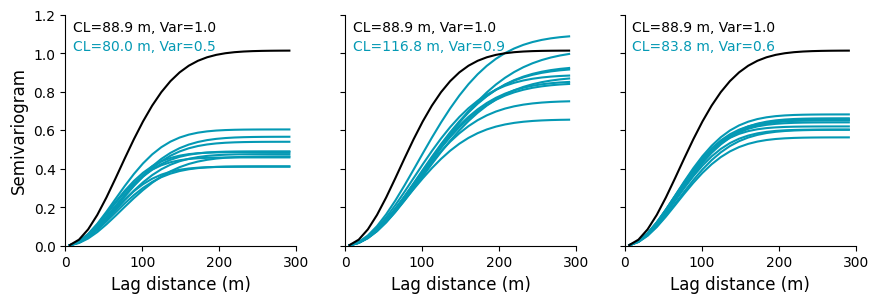

In [590]:
fig, axes = make_1x3(figsize=(10.5, 3), width_space=0.1)

super_vars, super_lens = [], []
sp_vars, sp_lens = [], []
ip_vars, ip_lens = [], []

for i in range(10):
    axes[0].plot(super_bin[i], super_fit[i].variogram(super_bin[i]), c=line_color, lw=1.5)
    super_vars.append(super_fit[i].var)
    super_lens.append(super_fit[i].len_scale)

    axes[1].plot(sp_bin[i], sp_fit[i].variogram(sp_bin[i]), c=line_color, lw=1.5)
    sp_vars.append(sp_fit[i].var)
    sp_lens.append(sp_fit[i].len_scale)

    axes[2].plot(ip_bin[i], ip_fit[i].variogram(ip_bin[i]), c=line_color, lw=1.5)
    ip_vars.append(ip_fit[i].var)
    ip_lens.append(ip_fit[i].len_scale)

super_vars = np.array(super_vars)
super_lens = np.array(super_lens)
sp_vars = np.array(sp_vars)
sp_lens = np.array(sp_lens)
ip_vars = np.array(ip_vars)
ip_lens = np.array(ip_lens)

axes[0].text(10, 1.1, f"CL={gt_fit.len_scale:.1f} m, Var={gt_fit.var:.1f}", fontsize=10,ha='left', va='bottom', c='k')
axes[0].text(10, 1.0, f"CL={super_lens.mean(axis=0):.1f} m, Var={super_vars.mean(axis=0):.1f}", fontsize=10,ha='left', va='bottom', c=line_color)

axes[1].text(10, 1.1, f"CL={gt_fit.len_scale:.1f} m, Var={gt_fit.var:.1f}", fontsize=10,ha='left', va='bottom', c='k')
axes[1].text(10, 1.0, f"CL={sp_lens.mean(axis=0):.1f} m, Var={sp_vars.mean(axis=0):.1f}", fontsize=10,ha='left', va='bottom', c=line_color)

axes[2].text(10, 1.1, f"CL={gt_fit.len_scale:.1f} m, Var={gt_fit.var:.1f}", fontsize=10,ha='left', va='bottom', c='k')
axes[2].text(10, 1.0, f"CL={ip_lens.mean(axis=0):.1f} m, Var={ip_vars.mean(axis=0):.1f}", fontsize=10,ha='left', va='bottom', c=line_color)


for a in axes:
    a.plot(gt_bin, gt_fit.variogram(gt_bin), c='k', lw=1.5)
    a.set_xlim(0, 300)
    a.set_ylim(0, 1.2)
    a.set_xlabel('Lag distance (m)', fontsize=12)
axes[0].set_ylabel('Semivariogram', fontsize=12)

fig.savefig('conditional_outputs/[rebuttle]figs/analysis-variogram.pdf', bbox_inches='tight')

#### Plum SSIM

torch.Size([64, 64, 64]) torch.Size([10, 64, 64, 64])
(10, 64) (10, 64)


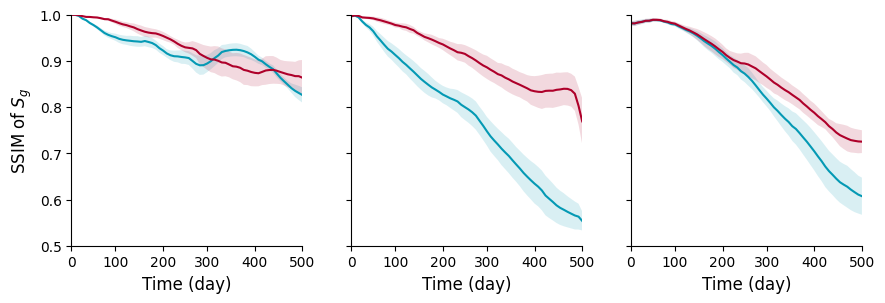

In [684]:
from skimage.metrics import structural_similarity as ssim
def compute_temporal_ssim(ref, gen):
    ref = ref.numpy()
    gen = gen.numpy()
    ssim_values = []
    for i in range(gen.shape[0]):
        ssim_t_values = []
        for t in range(gen.shape[1]):
            ssim_value = ssim(ref[t, :, :], gen[i, t, :, :], data_range=gen[i, t, :, :].max() - gen[i, t, :, :].min())
            ssim_t_values.append(ssim_value)
        ssim_values.append(np.array(ssim_t_values))
    return np.array(ssim_values)


def compute_gene_sim_ssim(sim, gen):
    sim = sim.numpy()
    gen = gen.numpy()
    ssim_values = []
    for i in range(gen.shape[0]):
        ssim_t_values = []
        for t in range(gen.shape[1]):
            ssim_value = ssim(sim[i, t, :, :], gen[i, t, :, :], data_range=gen[i, t, :, :].max() - gen[i, t, :, :].min())
            ssim_t_values.append(ssim_value)
        ssim_values.append(np.array(ssim_t_values))
    return np.array(ssim_values)


gt_s_field = gt[..., 1]
super_s_field = superres_pt[..., 1].clone()
sp_s_field = sparse_pt[..., 1].clone()
ip_s_field = inpaint_pt[..., 1].clone()

super_sims_field = torch.from_numpy(superres_sim['saturation'][:]).clone()
sp_sims_field = torch.from_numpy(sparse_sim['saturation'][:]).clone()
ip_sims_field = torch.from_numpy(inpaint_sim['saturation'][:]).clone()

thres_value = 0.02
super_s_field.masked_fill_(super_s_field < thres_value, 0)
sp_s_field.masked_fill_(sp_s_field < thres_value, 0)
ip_s_field.masked_fill_(ip_s_field < thres_value, 0)
super_sims_field.masked_fill_(super_sims_field < thres_value, 0)
sp_sims_field.masked_fill_(sp_sims_field < thres_value, 0)
ip_sims_field.masked_fill_(ip_sims_field < thres_value, 0)
print(gt_s_field.shape, super_s_field.shape)

super_gene_ssim = compute_temporal_ssim(gt_s_field, super_s_field)
sp_gene_ssim = compute_temporal_ssim(gt_s_field, sp_s_field)
ip_gene_ssim = compute_temporal_ssim(gt_s_field, ip_s_field)
super_sim_ssim = compute_gene_sim_ssim(super_sims_field, super_s_field)
sp_sim_ssim = compute_gene_sim_ssim(sp_sims_field, sp_s_field)
ip_sim_ssim = compute_gene_sim_ssim(ip_sims_field, ip_s_field)
print(super_gene_ssim.shape, super_sim_ssim.shape)

fig, axes = make_1x3(figsize=(10.5, 3), width_space=0.1)


def fill_between(ax, mean, std, color='grey'):
    ax.fill_between(np.arange(len(mean)), mean - std*1, mean + std*1, color=color, alpha=0.15, edgecolor='none')
red_color = '#ae002a'

axes[0].plot(super_gene_ssim.mean(axis=0), lw=1.5, c=line_color)
fill_between(axes[0], super_gene_ssim.mean(axis=0), super_gene_ssim.std(axis=0), color=line_color)
axes[0].plot(super_sim_ssim.mean(axis=0), lw=1.5, c=red_color)
fill_between(axes[0], super_sim_ssim.mean(axis=0), super_sim_ssim.std(axis=0), color=red_color)

axes[1].plot(sp_gene_ssim.mean(axis=0), lw=1.5, c=line_color)
fill_between(axes[1], sp_gene_ssim.mean(axis=0), sp_gene_ssim.std(axis=0), color=line_color)
axes[1].plot(sp_sim_ssim.mean(axis=0), lw=1.5, c=red_color)
fill_between(axes[1], sp_sim_ssim.mean(axis=0), sp_sim_ssim.std(axis=0), color=red_color)

axes[2].plot(ip_gene_ssim.mean(axis=0), lw=1.5, c=line_color)
fill_between(axes[2], ip_gene_ssim.mean(axis=0), ip_gene_ssim.std(axis=0), color=line_color)
axes[2].plot(ip_sim_ssim.mean(axis=0), lw=1.5, c=red_color)
fill_between(axes[2], ip_sim_ssim.mean(axis=0), ip_sim_ssim.std(axis=0), color=red_color)

for a in axes:
    a.set_ylim(0.5, 1.0)
    labels = [0, 100, 200, 300, 400, 500]
    positions = [int(x * 63 / 500) for x in labels]
    a.set_xlim(0, 63)
    a.set_xticks(ticks=positions, labels=[str(x) for x in labels])
    a.set_xlabel('Time (day)', fontsize=12)
axes[0].set_ylabel('SSIM of $S_g$', fontsize=12)

fig.savefig('conditional_outputs/[rebuttle]figs/analysis-sat-ssim.pdf', bbox_inches='tight')

#### Plume moment

In [3]:
gt_s_field = gt[..., 1]
super_s_field = superres_pt[..., 1].clone()
sp_s_field = sparse_pt[..., 1].clone()
ip_s_field = inpaint_pt[..., 1].clone()

super_sims_field = torch.from_numpy(superres_sim['saturation'][:]).clone()
sp_sims_field = torch.from_numpy(sparse_sim['saturation'][:]).clone()
ip_sims_field = torch.from_numpy(inpaint_sim['saturation'][:]).clone()

thres_value = 0.05
super_s_field.masked_fill_(super_s_field < thres_value, 0)
sp_s_field.masked_fill_(sp_s_field < thres_value, 0)
ip_s_field.masked_fill_(ip_s_field < thres_value, 0)
super_sims_field.masked_fill_(super_sims_field < thres_value, 0)
sp_sims_field.masked_fill_(sp_sims_field < thres_value, 0)
ip_sims_field.masked_fill_(ip_sims_field < thres_value, 0)
print(gt_s_field.shape, super_s_field.shape)

def gene_cartesian_coord():
    h = w = 64
    H = W = 640
    x_coord = np.linspace(0, H, h)
    y_coord = np.linspace(0, W, w)
    xx, yy = np.meshgrid(x_coord, y_coord, indexing='ij')
    xy_coord = np.stack((xx, yy), axis=-1)
    xy_coord = torch.tensor(xy_coord, dtype=torch.float32)
    return xy_coord

grid = gene_cartesian_coord()[..., 1]
print(grid.shape)

gt_m0 = gt_s_field.sum(dim=(1, 2))
super_m0 = super_s_field.sum(dim=(2, 3))
sp_m0 = sp_s_field.sum(dim=(2, 3))
ip_m0 = ip_s_field.sum(dim=(2, 3))
super_sim_m0 = super_sims_field.sum(dim=(2, 3))
sp_sim_m0 = sp_sims_field.sum(dim=(2, 3))
ip_sim_m0 = ip_sims_field.sum(dim=(2, 3))
print(gt_m0.shape, super_m0.shape)

gt_m1 = (gt_s_field * grid).sum(dim=(1, 2))
super_m1 = (super_s_field * grid).sum(dim=(2, 3))
sp_m1 = (sp_s_field * grid).sum(dim=(2, 3))
ip_m1 = (ip_s_field * grid).sum(dim=(2, 3))
super_sim_m1 = (super_sims_field * grid).sum(dim=(2, 3))
sp_sim_m1 = (sp_sims_field * grid).sum(dim=(2, 3))
ip_sim_m1 = (ip_sims_field * grid).sum(dim=(2, 3))
print(gt_m1.shape, super_m1.shape)

gt_center = gt_m1 / gt_m0
super_center = super_m1 / super_m0
sp_center = sp_m1 / sp_m0
ip_center = ip_m1 / ip_m0
super_sim_center = super_sim_m1 / super_sim_m0
sp_sim_center = sp_sim_m1 / sp_sim_m0
ip_sim_center = ip_sim_m1 / ip_sim_m0

torch.Size([64, 64, 64]) torch.Size([10, 64, 64, 64])
torch.Size([64, 64])
torch.Size([64]) torch.Size([10, 64])
torch.Size([64]) torch.Size([10, 64])


In [4]:
T = 500 / 64

gt_v = torch.diff(gt_center) / T
super_v = torch.diff(super_center, dim=1) / T
sp_v = torch.diff(sp_center, dim=1) / T
ip_v = torch.diff(ip_center, dim=1) / T
super_sim_v = torch.diff(super_sim_center, dim=1) / T
sp_sim_v = torch.diff(sp_sim_center, dim=1) / T
ip_sim_v = torch.diff(ip_sim_center, dim=1) / T
print(gt_v.shape, super_v.shape)

torch.Size([63]) torch.Size([10, 63])


In [599]:
super_v[0]

tensor([0.4395, 0.3961, 0.3509, 0.4318, 0.4349, 0.4450, 0.4277, 0.4062, 0.4320,
        0.3424, 0.4612, 0.4770, 0.4349, 0.4234, 0.4296, 0.4007, 0.4053, 0.4226,
        0.3799, 0.5227, 0.4300, 0.3933, 0.4252, 0.3763, 0.3495, 0.4600, 0.4764,
        0.4322, 0.4285, 0.3890, 0.6128, 0.4262, 0.4939, 0.5397, 0.5571, 0.5451,
        0.5200, 0.4387, 0.4482, 0.4037, 0.3688, 0.4267, 0.4062, 0.4201, 0.4867,
        0.5494, 0.3445, 0.4884, 0.4677, 0.4765, 0.4474, 0.5206, 0.4843, 0.4411,
        0.4257, 0.4547, 0.3794, 0.3749, 0.3763, 0.4029, 0.4776, 0.3736, 0.2973])

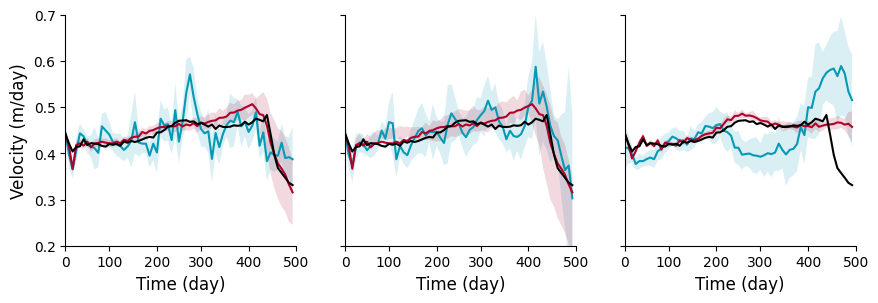

In [8]:
fig, axes = make_1x3(figsize=(10.5, 3), width_space=0.1)


def fill_between(ax, mean, std, color='grey'):
    ax.fill_between(np.arange(len(mean)), mean - std*1, mean + std*1, color=color, alpha=0.15, edgecolor='none')
red_color = '#ae002a'
line_color = '#0499b4'
axes[0].plot(super_v.mean(dim=0), lw=1.5, c=line_color)
fill_between(axes[0], super_v.mean(dim=0), super_v.std(dim=0), color=line_color)
axes[0].plot(super_sim_v.mean(dim=0), lw=1.5, c=red_color)
fill_between(axes[0], super_sim_v.mean(dim=0), super_sim_v.std(dim=0), color=red_color)

axes[1].plot(sp_v.mean(dim=0), lw=1.5, c=line_color)
fill_between(axes[1], sp_v.mean(dim=0), sp_v.std(dim=0), color=line_color)
axes[1].plot(super_sim_v.mean(dim=0), lw=1.5, c=red_color)
fill_between(axes[1], sp_sim_v.mean(dim=0), sp_sim_v.std(dim=0), color=red_color)

axes[2].plot(ip_v.mean(dim=0), lw=1.5, c=line_color)
fill_between(axes[2], ip_v.mean(dim=0), ip_v.std(dim=0), color=line_color)
axes[2].plot(ip_sim_v.mean(dim=0), lw=1.5, c=red_color)
fill_between(axes[2], ip_sim_v.mean(dim=0), ip_sim_v.std(dim=0), color=red_color)


for a in axes:
    a.plot(gt_v, lw=1.5, c='k')
    a.set_ylim(0.2, 0.7)
    labels = [0, 100, 200, 300, 400, 500]
    positions = [int(x * 63 / 500) for x in labels]
    a.set_xlim(0, 63)
    a.set_xticks(ticks=positions, labels=[str(x) for x in labels])
    a.set_xlabel('Time (day)', fontsize=12)
    # a.set_yticks([0.2, 0.3, 0.4, 0.5, 0.6])
axes[0].set_ylabel('Velocity (m/day)', fontsize=12)

fig.savefig('conditional_outputs/[rebuttle]figs/analysis-velocity.pdf', bbox_inches='tight')

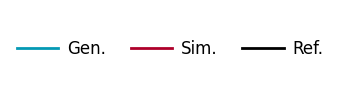

In [10]:
from matplotlib.lines import Line2D
legend_elements = [
    Line2D([0], [0], color='#0499b4', lw=2, ls='-', label='Gen.'),
    Line2D([0], [0], color='#ae002a', lw=2, ls='-', label='Sim.'),
    Line2D([0], [0], color='k', lw=2, ls='-', label='Ref.'),
]

fig, ax = plt.subplots(figsize=(3, 1))
ax.axis('off')

fig.legend(
    handles=legend_elements,
    loc='center',
    ncol=3,
    frameon=False,
    handlelength=2.5,  # length of the legend lines
    handletextpad=0.5,  # space between the legend line and the text
    columnspacing=1.5,  # space between columns
    labelspacing=2,    # space between rows
    fontsize=12,
)

# plt.tight_layout()
fig.savefig('conditional_outputs/[rebuttle]figs/LEGEND_line.pdf', bbox_inches='tight')
plt.show()

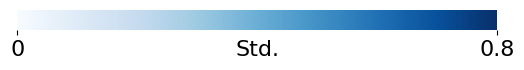

In [3]:
import matplotlib.colorbar as colorbar
import matplotlib.colors as colors


cmap = plt.get_cmap("Blues")
norm = colors.Normalize(vmin=0, vmax=0.8)
sm = plt.cm.ScalarMappable(cmap=cmap, norm=norm)
sm.set_array([])

fig = plt.figure(figsize=(6, 2))
cbar_ax = fig.add_axes([0.2, 0.5, 0.8, 0.1])

cbar = fig.colorbar(sm, cax=cbar_ax, orientation='horizontal')

cbar.set_ticks([0, 0.8])
cbar.ax.set_xticklabels(["0", "0.8"])
cbar.outline.set_visible(False)
cbar.ax.tick_params(labelsize=16)

cbar_ax.text(0.5, -1.0, "Std.", transform=cbar_ax.transAxes,
            fontsize=16, ha='center', va='center')

fig.savefig('conditional_outputs/[rebuttle]figs/LEGEND_Std.pdf', bbox_inches='tight')
plt.show()

#### sensitivity boxplot

In [4]:
superres_low_pt = torch.load('conditional_outputs/[rebuttle]pts/CNF_out_superresolution-4.pt', map_location='cpu')
sparse_low_pt = torch.load('conditional_outputs/pts/CNF_out_Cart1Sparse_All.pt', map_location='cpu')
inpaint_low_pt = torch.load('conditional_outputs/[rebuttle]pts/CNF_out_inpainting-25%.pt', map_location='cpu')

superres_high_pt = torch.load('conditional_outputs/[rebuttle]pts/CNF_out_superresolution-16.pt', map_location='cpu')
sparse_high_pt = torch.load('conditional_outputs/pts/CNF_out_Cart20Sparse_All.pt', map_location='cpu')
inpaint_high_pt = torch.load('conditional_outputs/[rebuttle]pts/CNF_out_inpainting-75%.pt', map_location='cpu')

In [5]:
from skimage.metrics import structural_similarity as ssim
def ensemble_ssim(ref, gen):
    ref = ref.numpy()
    gen = gen.numpy()
    ssim_list = []
    for i in range(gen.shape[0]):
        ssim_value = ssim(ref, gen[i], data_range=gen[i].max() - gen[i].min())
        ssim_list.append(ssim_value)
    return np.array(ssim_list)

gt_k_field = gt[0, :, :, -1]
super_low_k_field = superres_low_pt[..., -1].mean(dim=1)
super_mid_k_field = superres_pt[..., -1].mean(dim=1)
super_high_k_field = superres_high_pt[..., -1].mean(dim=1)

sp_low_k_field = sparse_low_pt[..., -1].mean(dim=1)
sp_mid_k_field = sparse_pt[..., -1].mean(dim=1)
sp_high_k_field = sparse_high_pt[..., -1].mean(dim=1)

ip_low_k_field = inpaint_low_pt[..., -1].mean(dim=1)
ip_mid_k_field = inpaint_pt[..., -1].mean(dim=1)
ip_high_k_field = inpaint_high_pt[..., -1].mean(dim=1)

print(gt_k_field.shape, super_low_k_field.shape)
super_low_k_ssim = ensemble_ssim(gt_k_field, super_low_k_field)
super_mid_k_ssim = ensemble_ssim(gt_k_field, super_mid_k_field)
super_high_k_ssim = ensemble_ssim(gt_k_field, super_high_k_field)
sp_low_k_ssim = ensemble_ssim(gt_k_field, sp_low_k_field)
sp_mid_k_ssim = ensemble_ssim(gt_k_field, sp_mid_k_field)
sp_high_k_ssim = ensemble_ssim(gt_k_field, sp_high_k_field)
ip_low_k_ssim = ensemble_ssim(gt_k_field, ip_low_k_field)
ip_mid_k_ssim = ensemble_ssim(gt_k_field, ip_mid_k_field)
ip_high_k_ssim = ensemble_ssim(gt_k_field, ip_high_k_field)

print(super_low_k_ssim.shape)

torch.Size([64, 64]) torch.Size([10, 64, 64])
(10,)


In [15]:
gt_s_field = gt[-1, ..., 1]
super_low_s_field = superres_low_pt[:, -1, ..., 1]
super_mid_s_field = superres_pt[:, -1, ..., 1]
super_high_s_field = superres_high_pt[:, -1, ..., 1]

sp_low_s_field = sparse_low_pt[:, -1, ..., 1]
sp_mid_s_field = sparse_pt[:, -1, ..., 1]
sp_high_s_field = sparse_high_pt[:, -1, ..., 1]

ip_low_s_field = inpaint_low_pt[:, -1, ..., 1]
ip_mid_s_field = inpaint_pt[:, -1, ..., 1]
ip_high_s_field = inpaint_high_pt[:, -1, ..., 1]

print(gt_s_field.shape, super_low_s_field.shape)
super_low_s_ssim = ensemble_ssim(gt_s_field, super_low_s_field)
super_mid_s_ssim = ensemble_ssim(gt_s_field, super_mid_s_field)
super_high_s_ssim = ensemble_ssim(gt_s_field, super_high_s_field)
sp_low_s_ssim = ensemble_ssim(gt_s_field, sp_low_s_field)
sp_mid_s_ssim = ensemble_ssim(gt_s_field, sp_mid_s_field)
sp_high_s_ssim = ensemble_ssim(gt_s_field, sp_high_s_field)
ip_low_s_ssim = ensemble_ssim(gt_s_field, ip_low_s_field)
ip_mid_s_ssim = ensemble_ssim(gt_s_field, ip_mid_s_field)
ip_high_s_ssim = ensemble_ssim(gt_s_field, ip_high_s_field)
print(super_low_s_ssim.shape)

torch.Size([64, 64]) torch.Size([10, 64, 64])
(10,)


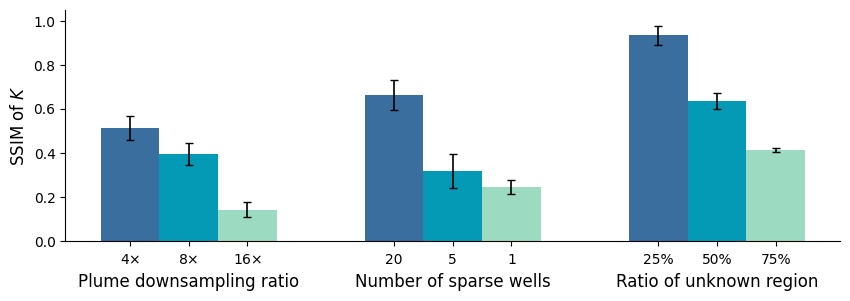

In [28]:
data = np.array([
    [super_high_k_ssim.mean(), super_mid_k_ssim.mean(), super_low_k_ssim.mean()],
    [sp_high_k_ssim.mean(), sp_mid_k_ssim.mean(), sp_low_k_ssim.mean()],
    [ip_high_k_ssim.mean(), ip_mid_k_ssim.mean(), ip_low_k_ssim.mean()],
])
std = np.array([
    [super_low_k_ssim.std(), super_mid_k_ssim.std(), super_high_k_ssim.std()],
    [sp_low_k_ssim.std(), sp_mid_k_ssim.std(), sp_high_k_ssim.std()],
    [ip_low_k_ssim.std(), ip_mid_k_ssim.std(), ip_high_k_ssim.std()],
])

group_names = ['Plume downsampling ratio', 'Number of sparse wells', 'Ratio of unknown region']
bar_labels = [
    [r'4$\times$', r'8$\times$', r'16$\times$'],
    ['20', '5', '1'],
    ['25%', '50%', '75%'],
]
colors = ['#9ddac2', '#0499b4', '#3a6e9f'][::-1]

n_groups, n_bars = data.shape
bar_width = 0.2
group_gap = 0.3

x = np.arange(n_groups) * (n_bars * bar_width + group_gap)

fig, ax = plt.subplots(figsize=(10, 3))
for i in range(n_bars):
    ax.bar(x + i * bar_width, data[:, i], bar_width,
           yerr=std[:, i], capsize=3, error_kw={'lw': 1.2}, color=colors[i])

tick_positions = []
tick_labels = []
for g in range(n_groups):
    for b in range(n_bars):
        tick_positions.append(x[g] + b * bar_width)
        tick_labels.append(bar_labels[g][b])

ax.set_xticks(tick_positions)
ax.set_xticklabels(tick_labels, fontsize=8)

for g in range(n_groups):
    group_center = x[g] + (n_bars - 1) * bar_width / 2
    ax.text(group_center, -0.2, group_names[g], ha='center', fontsize=12,
            transform=ax.get_xaxis_transform())

ax.tick_params(axis='x', pad=5,labelsize=10)
ax.spines['right'].set_visible(False)
ax.spines['top'].set_visible(False)
ax.set_ylim(0.0, 1.05)
ax.set_ylabel('SSIM of $K$', fontsize=12)
# plt.tight_layout()
fig.savefig('conditional_outputs/[rebuttle]figs/analysis-Kssim-bar.pdf', bbox_inches='tight')
plt.show()

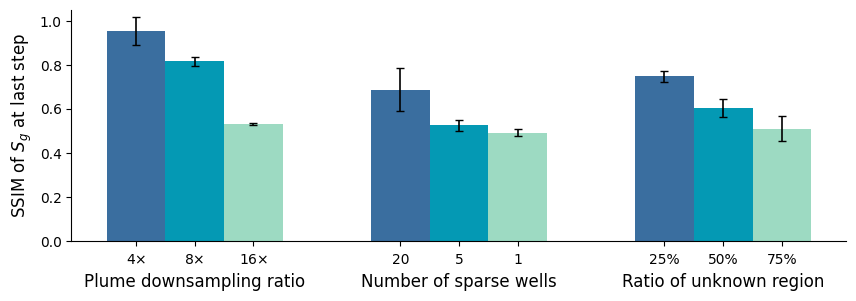

In [29]:
data = np.array([
    [super_high_s_ssim.mean(), super_mid_s_ssim.mean(), super_low_s_ssim.mean()],
    [sp_high_s_ssim.mean(), sp_mid_s_ssim.mean(), sp_low_s_ssim.mean()],
    [ip_high_s_ssim.mean(), ip_mid_s_ssim.mean(), ip_low_s_ssim.mean()],
])
std = np.array([
    [super_low_s_ssim.std(), super_mid_s_ssim.std(), super_high_s_ssim.std()],
    [sp_low_s_ssim.std(), sp_mid_s_ssim.std(), sp_high_s_ssim.std()],
    [ip_low_s_ssim.std(), ip_mid_s_ssim.std(), ip_high_s_ssim.std()],
])

group_names = ['Plume downsampling ratio', 'Number of sparse wells', 'Ratio of unknown region']
bar_labels = [
    [r'4$\times$', r'8$\times$', r'16$\times$'],
    ['20', '5', '1'],
    ['25%', '50%', '75%'],
]
colors = ['#9ddac2', '#0499b4', '#3a6e9f'][::-1]

n_groups, n_bars = data.shape
bar_width = 0.2
group_gap = 0.3

x = np.arange(n_groups) * (n_bars * bar_width + group_gap)

fig, ax = plt.subplots(figsize=(10, 3))
for i in range(n_bars):
    ax.bar(x + i * bar_width, data[:, i], bar_width,
           yerr=std[:, i], capsize=3, error_kw={'lw': 1.2}, color=colors[i])

tick_positions = []
tick_labels = []
for g in range(n_groups):
    for b in range(n_bars):
        tick_positions.append(x[g] + b * bar_width)
        tick_labels.append(bar_labels[g][b])

ax.set_xticks(tick_positions)
ax.set_xticklabels(tick_labels, fontsize=8)

for g in range(n_groups):
    group_center = x[g] + (n_bars - 1) * bar_width / 2
    ax.text(group_center, -0.2, group_names[g], ha='center', fontsize=12,
            transform=ax.get_xaxis_transform())

ax.tick_params(axis='x', pad=5,labelsize=10)
ax.spines['right'].set_visible(False)
ax.spines['top'].set_visible(False)
ax.set_ylim(0.0, 1.05)
ax.set_ylabel('SSIM of $S_g$ at last step', fontsize=12)
# plt.tight_layout()
fig.savefig('conditional_outputs/[rebuttle]figs/analysis-Sssim-bar.pdf', bbox_inches='tight')
plt.show()